In [11]:
import pandas as pd
import datetime
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import numpy as np
import scipy
import plotly.express as px
import requests
import io
import streamlit as st

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_rows', 1000) # Display more row of your dataframe
pd.options.display.float_format = '{:,}'.format # Separate number with comma


In [12]:


#Appel de l'API pour récupérer les nom des colonnes disponibles dans le dataset "soldats-morts-pour-la-france-nes-en-corse"
BASE = "https://data.corsica/data-fair/api/v1/datasets/soldats-morts-pour-la-france-nes-en-corse"


# 5 lignes d'exemple, toutes colonnes
df = pd.read_csv(f"{BASE}/lines?format=csv&size=5")
colonnes =[]
for col in df.columns:
    colonnes.append(col)

print(f"Colonnes disponibles : {colonnes}")

params = {
    "format": "csv",
    "select": ",".join(colonnes),
    "size": 10000,   # maximum par page
}

Colonnes disponibles : ['nom', 'prenom', 'conflit', 'date_deces', 'departement', 'nom_departement', 'connexion']


In [18]:
#appel de l'API pour créer le dataset "soldats-morts-pour-la-france-nes-en-corse"

url = f"{BASE}/lines"
params = {"select": ",".join(colonnes), "size": 10000}
lignes = []

while url:
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    data = r.json()
    lignes.extend(data["results"])
    url = data.get("next")
    params = None   # l'URL "next" contient déjà les paramètres

df = pd.DataFrame(lignes)
df["date_deces"] = pd.to_datetime(df["date_deces"], errors="coerce")
df["annee_deces"] = df["date_deces"].dt.year
df = df[df["annee_deces"] >= 1910]
df = df[df["annee_deces"] <= 1960]
df.to_csv("csv/soldats_corse.csv", index=False)

## 3) Data visualisation des soldats morts pour la France

Cette section propose une vue d'ensemble des données : qualité, répartition par conflit et département, évolution temporelle des décès, et principaux résultats.

In [3]:
from analysis_data import load_analysis_data

data = load_analysis_data()
viz = data["viz"]
resume_conflits = data["resume_conflits"]
resume_departements = data["resume_departements"]
par_annee = data["par_annee"]
par_decennie = data["par_decennie"]
prenoms = data["prenoms"]
synthese = data["synthese"]

print(f"Nombre de soldats : {len(viz):,}")
print(f"Dates de décès renseignées : {viz['date_deces'].notna().sum():,}")
print(f"Dates de décès manquantes : {viz['date_deces'].isna().sum():,}")
resume_conflits

Nombre de soldats : 12,095
Dates de décès renseignées : 11,493
Dates de décès manquantes : 602


,conflit,soldats
0,1914-1918,10105
1,1939-1945,1661
2,Indochine,173
3,Guerre d'Algérie,55
4,1870-1871,25
5,Maroc,22
6,Levant,15
7,Hors conflit,11
8,Crimée,5
9,Corée,5


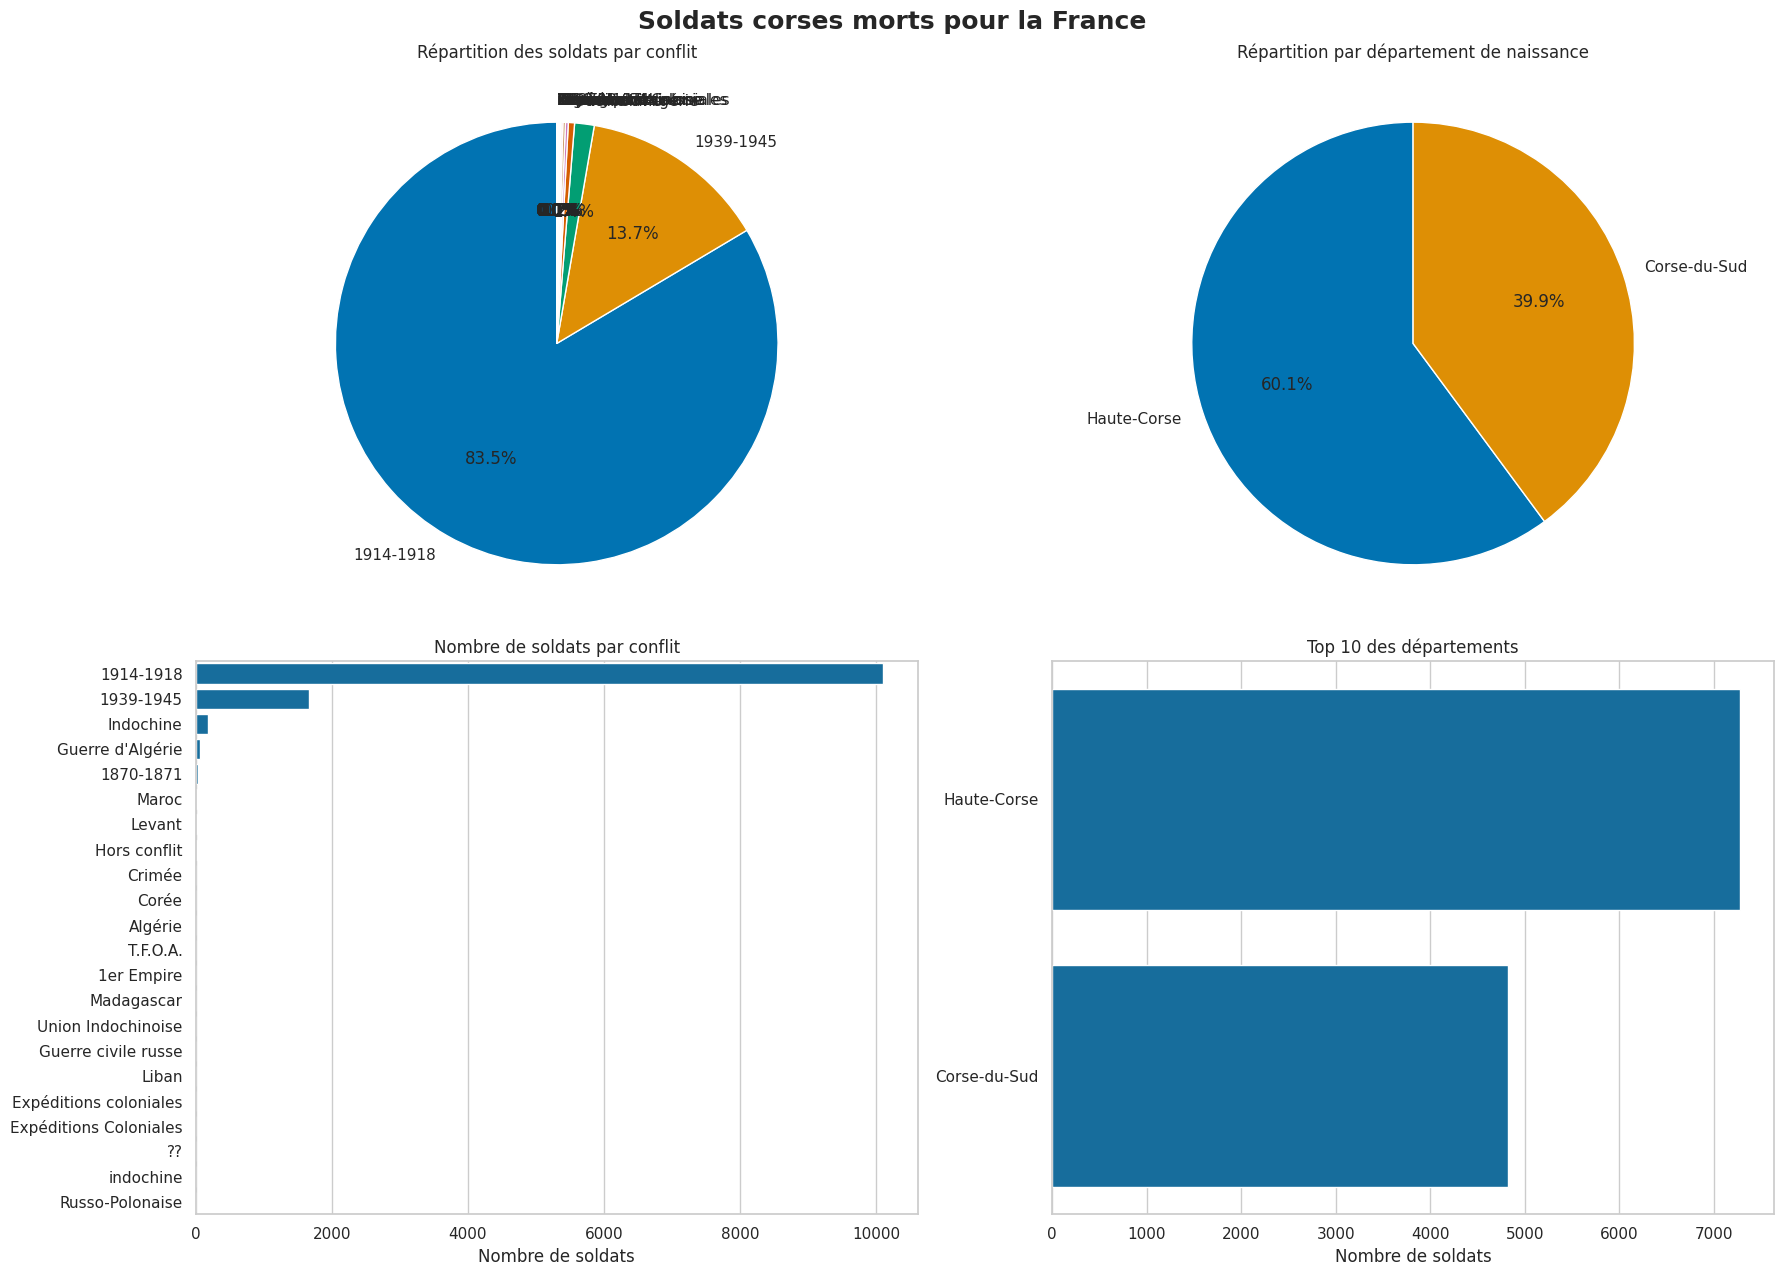

In [10]:
# Tableau de bord principal : conflits, départements et évolution temporelle
sns.set_theme(style="whitegrid", palette="colorblind")
fig, axes = plt.subplots(2, 2, figsize=(18, 13))

# 1. Camembert de la répartition par conflit
axes[0, 0].pie(
    resume_conflits["soldats"],
    labels=resume_conflits["conflit"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"linewidth": 1, "edgecolor": "white"},
)
axes[0, 0].set_title("Répartition des soldats par conflit")

# 2. Camembert des départements
axes[0, 1].pie(
    resume_departements["soldats"],
    labels=resume_departements["departement"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"linewidth": 1, "edgecolor": "white"},
)
axes[0, 1].set_title("Répartition par département de naissance")

# 3. Barres horizontales par conflit
sns.barplot(
    data=resume_conflits,
    y="conflit",
    x="soldats",
    ax=axes[1, 0],
    order=resume_conflits["conflit"].unique(),
)
axes[1, 0].set_title("Nombre de soldats par conflit")
axes[1, 0].set_xlabel("Nombre de soldats")
axes[1, 0].set_ylabel("")

# 4. Top départements
sns.barplot(
    data=resume_departements.head(10),
    y="departement",
    x="soldats",
    ax=axes[1, 1],
    order=resume_departements.head(10)["departement"],
)
axes[1, 1].set_title("Top 10 des départements")
axes[1, 1].set_xlabel("Nombre de soldats")
axes[1, 1].set_ylabel("")

plt.suptitle("Soldats corses morts pour la France", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.show()

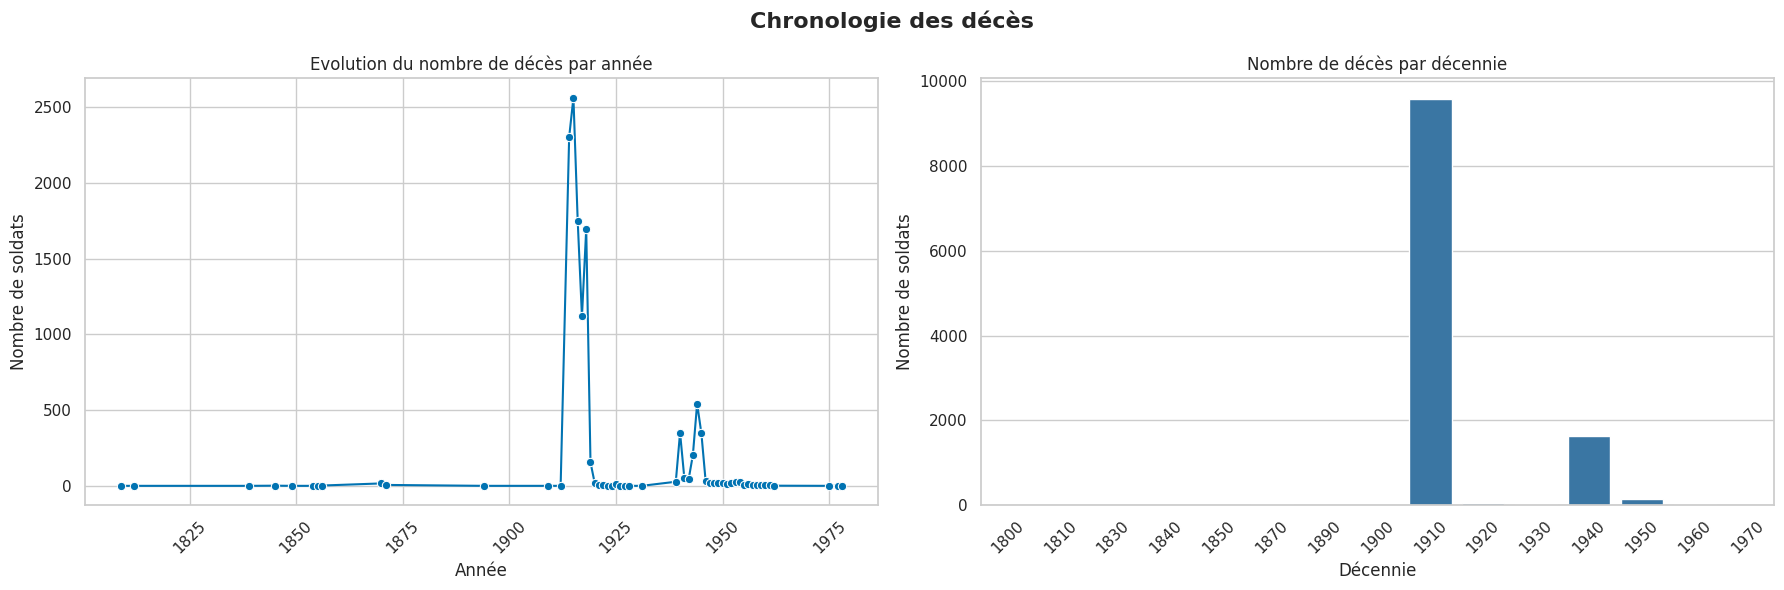

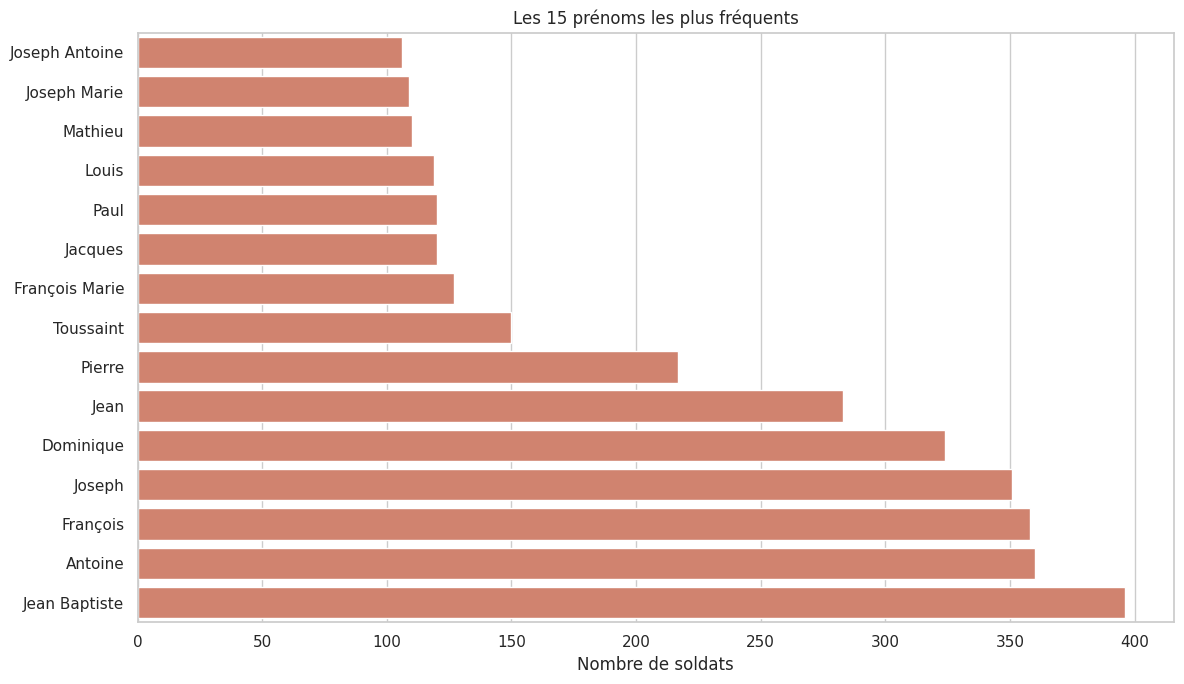

,Indicateur,Valeur
0,Nombre total de soldats,"12,095"
1,Nombre de conflits,22
2,Département le plus représenté,Haute-Corse
3,Conflit le plus représenté,1914-1918
4,Année avec le plus de décès renseignés,1915


In [ ]:
# Evolution temporelle des décès et répartition des prénoms
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Décès par année
par_annee = (
    viz.dropna(subset=["annee_deces"])
    .groupby("annee_deces")
    .size()
    .rename("soldats")
    .reset_index()
)
sns.lineplot(data=par_annee, x="annee_deces", y="soldats", marker="o", ax=axes[0])
axes[0].set_title("Evolution du nombre de décès par année")
axes[0].set_xlabel("Année")
axes[0].set_ylabel("Nombre de soldats")
axes[0].tick_params(axis="x", rotation=45)

# Décès par décennie
par_decennie = (
    viz.dropna(subset=["decennie"])
    .groupby("decennie")
    .size()
    .rename("soldats")
    .reset_index()
)
sns.barplot(data=par_decennie, x="decennie", y="soldats", ax=axes[1], color="#2878b5")
axes[1].set_title("Nombre de décès par décennie")
axes[1].set_xlabel("Décennie")
axes[1].set_ylabel("Nombre de soldats")
axes[1].tick_params(axis="x", rotation=45)

plt.suptitle("Chronologie des décès", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# Les 15 prénoms les plus fréquents
prenoms = (
    viz["prenom"]
    .value_counts()
    .head(15)
    .sort_values()
    .rename_axis("prenom")
    .reset_index(name="soldats")
)
plt.figure(figsize=(12, 7))
sns.barplot(data=prenoms, y="prenom", x="soldats", color="#e07a5f")
plt.title("Les 15 prénoms les plus fréquents")
plt.xlabel("Nombre de soldats")
plt.ylabel("")
plt.tight_layout()
plt.show()

# Tableau de synthèse final
synthese = pd.DataFrame({
    "Indicateur": [
        "Nombre total de soldats",
        "Nombre de conflits",
        "Département le plus représenté",
        "Conflit le plus représenté",
        "Année avec le plus de décès renseignés",
    ],
    "Valeur": [
        f"{len(viz):,}",
        viz["conflit"].nunique(),
        resume_departements.iloc[0]["departement"],
        resume_conflits.iloc[0]["conflit"],
        int(par_annee.loc[par_annee["soldats"].idxmax(), "annee_deces"]),
    ],
})
synthese

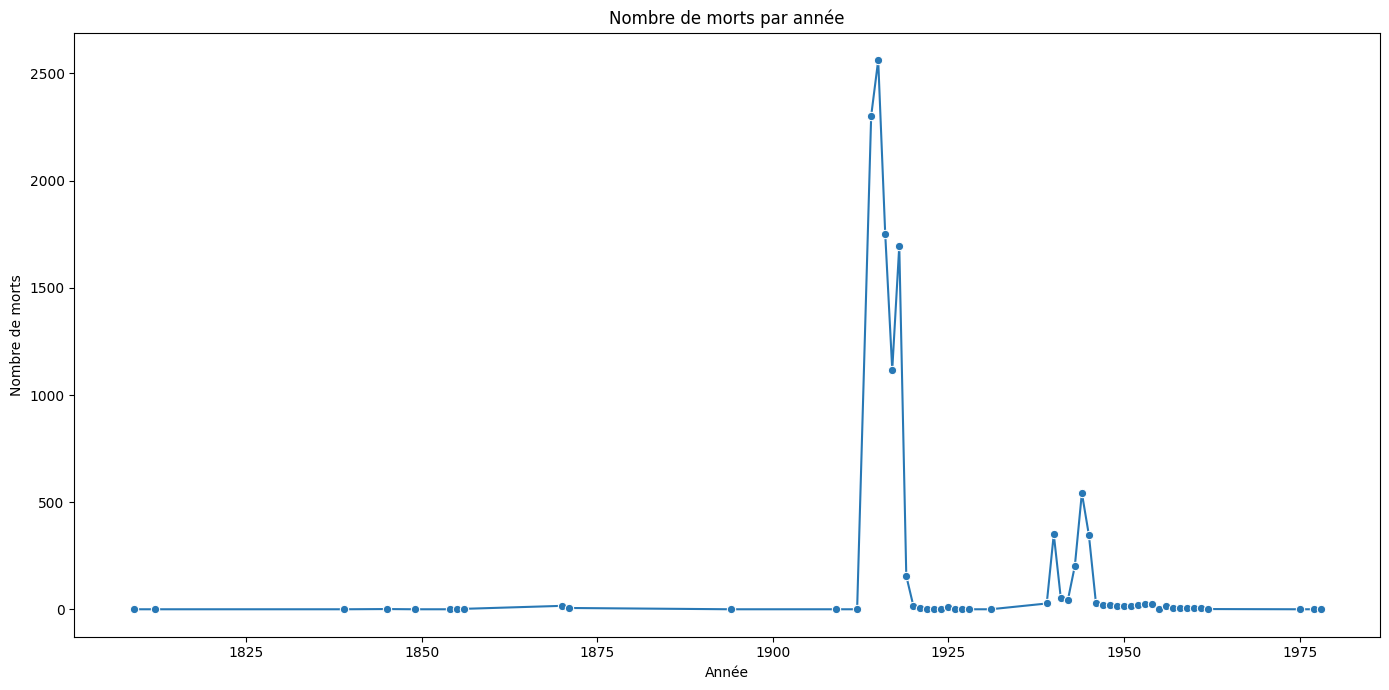

In [9]:
# Courbe du nombre de morts par année, de la plus ancienne à la plus récente
par_annee_graphique = par_annee.sort_values("annee_deces")

plt.figure(figsize=(14, 7))
sns.lineplot(
    data=par_annee_graphique,
    x="annee_deces",
    y="soldats",
    marker="o",
    color="#2878b5",
)
plt.title("Nombre de morts par année")
plt.xlabel("Année")
plt.ylabel("Nombre de morts")
plt.tight_layout()
plt.show()

In [ ]:
st.write("## Tableau de synthèse")
st.dataframe(synthese)

2026-10-22 13:27:12.722 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-22 13:27:12.827 
  command:

    streamlit run /home/coffeeshop/Documents/data-corsica-python/.micromamba/envs/default/lib/python3.12/site-packages/ipykernel_launcher.py [ARGUMENTS]
2026-10-22 13:27:12.828 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-22 13:27:12.828 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-22 13:27:13.102 Serialization of dataframe to Arrow table was unsuccessful. Applying automatic fixes for column types to make the dataframe Arrow-compatible.
Traceback (most recent call last):
  File "/home/coffeeshop/Documents/data-corsica-python/.micromamba/envs/default/lib/python3.12/site-packages/streamlit/dataframe_util.py", line 957, in convert_pandas

2026-10-22 13:27:12.722 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-22 13:27:12.827 
  command:

    streamlit run /home/coffeeshop/Documents/data-corsica-python/.micromamba/envs/default/lib/python3.12/site-packages/ipykernel_launcher.py [ARGUMENTS]
2026-10-22 13:27:12.828 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-22 13:27:12.828 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-22 13:27:13.102 Serialization of dataframe to Arrow table was unsuccessful. Applying automatic fixes for column types to make the dataframe Arrow-compatible.
Traceback (most recent call last):
  File "/home/coffeeshop/Documents/data-corsica-python/.micromamba/envs/default/lib/python3.12/site-packages/streamlit/dataframe_util.py", line 957, in convert_pandas

DeltaGenerator()